In [1]:
from pathlib import Path
import copy, json, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

print("PyTorch:", torch.__version__)


C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.0+cu130


## 1. Confirming CUDA is being used

In [3]:
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch: 2.14.0+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Reproducibility

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print("Seed:", SEED)


Seed: 42


## 3. Locating the project


In [5]:
def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "baseline_vit_b16"
FIGURE_DIR = REPORT_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 4. Loading the exact ResNet50 split

In [6]:
SPLIT_PATH = DATA_DIR / "interim" / "compcars_resnet50_baseline_split.csv"

if not SPLIT_PATH.exists():
    raise FileNotFoundError(f"Missing split file: {SPLIT_PATH}")

df = pd.read_csv(SPLIT_PATH)

print("Rows:", len(df))
print(df["split"].value_counts())
print("Unique classes:", df["class_name"].nunique())
display(df.head())


Rows: 2000
split
train    1600
val       200
test      200
Name: count, dtype: int64
Unique classes: 20


,file_path,make,model_name,body_type,width,height,source_dataset,image_hash,class_name,target,split
0,/content/drive/MyDrive/capstone-vehicle-metada...,Benz,Benz E Class couple,sedan,908,626,compcars,077d291611baf4e96cc1574af22737c5,Benz | Benz E Class couple,7,train
1,/content/drive/MyDrive/capstone-vehicle-metada...,Volkswagen,Golf,hatchback,908,626,compcars,0bc219f3f17c35ea52630de5dbe6f4e7,Volkswagen | Golf,18,train
2,/content/drive/MyDrive/capstone-vehicle-metada...,Ford,New Focus hatchback,hatchback,800,484,compcars,79f6bb7b0072188892db3ffbc5988686,Ford | New Focus hatchback,13,train
3,/content/drive/MyDrive/capstone-vehicle-metada...,Toyota,Camry,sedan,908,626,compcars,a3268fa1dd73a3df32b82efab22dc711,Toyota | Camry,17,train
4,/content/drive/MyDrive/capstone-vehicle-metada...,Audi,Audi A5 hatchback,fastback,908,626,compcars,ebbf4b4d936ed9a52ff6f4147e0063e8,Audi | Audi A5 hatchback,1,train


## 5. Validating the split

In [7]:
required = {"file_path", "class_name", "target", "split"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

NUM_CLASSES = df["target"].nunique()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", NUM_CLASSES)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    counts = part["target"].value_counts()
    print(f"{name}: min/class={counts.min()}, max/class={counts.max()}")


Train: 1600
Validation: 200
Test: 200
Classes: 20
train: min/class=80, max/class=80
val: min/class=10, max/class=10
test: min/class=10, max/class=10


## 6. Configure the CompCars image location




In [10]:
LOCAL_COMPCARS_EXTRACTED = Path(
    r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

if not LOCAL_COMPCARS_EXTRACTED.exists():
    raise FileNotFoundError(
        f"CompCars folder does not exist:\n{LOCAL_COMPCARS_EXTRACTED}"
    )

print("CompCars root:", LOCAL_COMPCARS_EXTRACTED)
print("Image folder exists:", (LOCAL_COMPCARS_EXTRACTED / "image").exists())


CompCars root: G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\compcars_kaggle\extracted
Image folder exists: True


## 7. Reconstructing local image paths

In [11]:
def resolve_local_path(original_path):
    text = str(original_path).replace("\\", "/")

    if "/extracted/" in text:
        relative = text.split("/extracted/", 1)[1]
        return LOCAL_COMPCARS_EXTRACTED / Path(*relative.split("/"))

    if "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
        return LOCAL_COMPCARS_EXTRACTED / Path(*relative.split("/"))

    return Path(original_path)

for part in [train_df, val_df, test_df]:
    part["local_file_path"] = part["file_path"].map(resolve_local_path)

display(train_df[["file_path", "local_file_path", "class_name"]].head(3))


,file_path,local_file_path,class_name
0,/content/drive/MyDrive/capstone-vehicle-metada...,G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...,Benz | Benz E Class couple
1,/content/drive/MyDrive/capstone-vehicle-metada...,G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...,Volkswagen | Golf
2,/content/drive/MyDrive/capstone-vehicle-metada...,G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...,Ford | New Focus hatchback


## 8. Quick path check

In [12]:
sample = pd.concat([train_df, val_df, test_df], ignore_index=True).sample(30, random_state=SEED)
exists = sample["local_file_path"].map(Path.exists)

print("Checked:", len(sample))
print("Existing:", int(exists.sum()))
print("Missing:", int((~exists).sum()))

if not exists.all():
    raise FileNotFoundError("Some image paths do not resolve.")

print("Path mapping looks good.")


Checked: 30
Existing: 30
Missing: 0
Path mapping looks good.


## 9. Class mapping

In [13]:
target_mapping = (
    df[["target", "class_name"]]
    .drop_duplicates()
    .sort_values("target")
)

class_names = target_mapping["class_name"].tolist()
display(target_mapping)


,target,class_name
8,0,Audi | Audi A5 coupe
4,1,Audi | Audi A5 hatchback
6,2,Audi | Audi A8L
21,3,BAW | BAW E Series hatchback
10,4,BWM | BWM 3 Series
11,5,BWM | BWM 5 Series
9,6,Benz | Benz E Class
0,7,Benz | Benz E Class couple
12,8,Buck | EXCELLE GT
7,9,Buck | Lacrosse


## 10. ViT-B/16 preprocessing

In [14]:
IMAGE_SIZE = 224
weights = ViT_B_16_Weights.DEFAULT

mean = weights.transforms().mean
std = weights.transforms().std

print("Mean:", mean)
print("Std:", std)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.0),
        ratio=(0.85, 1.15),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]


## 11. Dataset

In [15]:
class CompCarsDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(row["local_file_path"]).convert("RGB")
        target = int(row["target"])

        if self.transform:
            image = self.transform(image)

        return image, target

train_dataset = CompCarsDataset(train_df, train_transform)
val_dataset = CompCarsDataset(val_df, eval_transform)
test_dataset = CompCarsDataset(test_df, eval_transform)

print(len(train_dataset), len(val_dataset), len(test_dataset))


1600 200 200


## 12. DataLoaders



In [16]:
BATCH_SIZE = 8
NUM_WORKERS = 0

kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
}

train_loader = DataLoader(train_dataset, shuffle=True, **kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **kwargs)

images, targets = next(iter(train_loader))
print("Batch images:", images.shape)
print("Batch targets:", targets.shape)


Batch images: torch.Size([8, 3, 224, 224])
Batch targets: torch.Size([8])


## 13. Creating pretrained ViT-B/16

In [17]:
model = vit_b_16(weights=weights)

for parameter in model.parameters():
    parameter.requires_grad = False

in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, NUM_CLASSES)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Architecture: ViT-B/16")
print("Classes:", NUM_CLASSES)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters stage 1: {trainable_params:,}")
print("Model device:", next(model.parameters()).device)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\elesh/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 60.3MB/s] 


Architecture: ViT-B/16
Classes: 20
Total parameters: 85,814,036
Trainable parameters stage 1: 15,380
Model device: cuda:0


## 14. Training utilities

In [18]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=True)

def topk_correct(logits, targets, k=5):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    return topk.eq(targets.view(-1, 1)).any(dim=1).sum().item()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    running_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    samples = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=True):
            logits = model(images)
            loss = criterion(logits, targets)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        top1_correct += (logits.argmax(dim=1) == targets).sum().item()
        top5_correct += topk_correct(logits, targets, k=5)
        samples += batch_size

    return {
        "loss": running_loss / samples,
        "top1": top1_correct / samples,
        "top5": top5_correct / samples,
    }

def train_epochs(model, train_loader, val_loader, optimizer, epochs, stage_name):
    history = []
    best_state = copy.deepcopy(model.state_dict())
    best_val_top1 = -1.0

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        train_metrics = run_epoch(model, train_loader, optimizer)

        with torch.inference_mode():
            val_metrics = run_epoch(model, val_loader)

        elapsed = time.perf_counter() - start

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "train_top5": train_metrics["top5"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": elapsed,
        }

        history.append(row)

        print(
            f"[{stage_name}] Epoch {epoch:02d}/{epochs} | "
            f"train loss={row['train_loss']:.4f} top1={row['train_top1']:.3f} | "
            f"val loss={row['val_loss']:.4f} top1={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} | {elapsed:.1f}s"
        )

        if row["val_top1"] > best_val_top1:
            best_val_top1 = row["val_top1"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return history, best_val_top1


## 15. Stage 1: Training classification head

In [19]:
STAGE1_EPOCHS = 3

optimizer = torch.optim.AdamW(
    model.heads.head.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

history_stage1, stage1_best_val = train_epochs(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=STAGE1_EPOCHS,
    stage_name="head",
)

stage1_state = copy.deepcopy(model.state_dict())

print("Best Stage 1 validation Top-1:", stage1_best_val)


[head] Epoch 01/3 | train loss=2.4381 top1=0.303 | val loss=2.1626 top1=0.415 top5=0.825 | 2541.1s


[head] Epoch 02/3 | train loss=1.7953 top1=0.593 | val loss=1.8656 top1=0.595 top5=0.895 | 40.7s


[head] Epoch 03/3 | train loss=1.5008 top1=0.736 | val loss=1.7302 top1=0.555 top5=0.925 | 34.8s
Best Stage 1 validation Top-1: 0.595


## 16. Stage 2 : Fine-tuning the final transformer block



In [20]:
for parameter in model.encoder.layers[-1].parameters():
    parameter.requires_grad = True

for parameter in model.encoder.ln.parameters():
    parameter.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters stage 2: {trainable_params:,}")

STAGE2_EPOCHS = 3

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5,
    weight_decay=1e-4,
)

history_stage2, stage2_best_val = train_epochs(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=STAGE2_EPOCHS,
    stage_name="last_block_finetune",
)

print("Best Stage 2 validation Top-1:", stage2_best_val)


Trainable parameters stage 2: 7,104,788


[last_block_finetune] Epoch 01/3 | train loss=1.3678 top1=0.757 | val loss=1.5612 top1=0.635 top5=0.955 | 37.6s


[last_block_finetune] Epoch 02/3 | train loss=1.1000 top1=0.881 | val loss=1.4289 top1=0.715 top5=0.965 | 38.5s


[last_block_finetune] Epoch 03/3 | train loss=0.9393 top1=0.943 | val loss=1.3563 top1=0.720 top5=0.970 | 36.9s
Best Stage 2 validation Top-1: 0.72


## 17. Selecting the better validation checkpoint

In [21]:
if stage2_best_val >= stage1_best_val:
    selected_stage = "stage2_last_block_finetune"
    selected_val_top1 = stage2_best_val
    print("Using Stage 2 checkpoint.")
else:
    selected_stage = "stage1_head_only"
    selected_val_top1 = stage1_best_val
    model.load_state_dict(stage1_state)
    print("Restored Stage 1 checkpoint.")

print("Selected validation Top-1:", selected_val_top1)


Using Stage 2 checkpoint.
Selected validation Top-1: 0.72


## 18. Training curves

,stage,epoch,train_loss,train_top1,train_top5,val_loss,val_top1,val_top5,seconds
0,head,1,2.438080,0.303125,0.675625,2.162631,0.415,0.825,2541.053970
1,head,2,1.795253,0.593125,0.918750,1.865594,0.595,0.895,40.677160
2,head,3,1.500843,0.735625,0.960000,1.730170,0.555,0.925,34.831151
3,last_block_finetune,1,1.367828,0.756875,0.970625,1.561201,0.635,0.955,37.553592
4,last_block_finetune,2,1.099989,0.880625,0.995625,1.428868,0.715,0.965,38.546521
5,last_block_finetune,3,0.939315,0.943125,0.998125,1.356320,0.720,0.970,36.894453


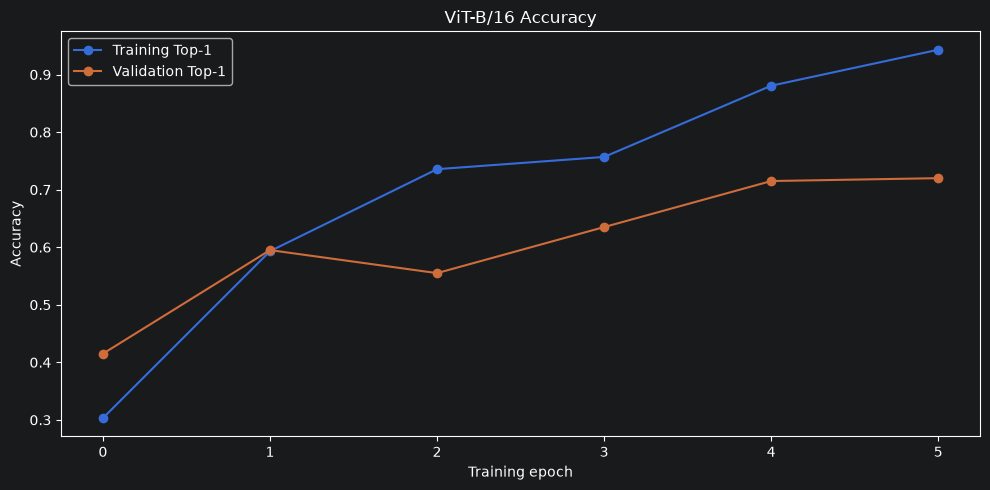

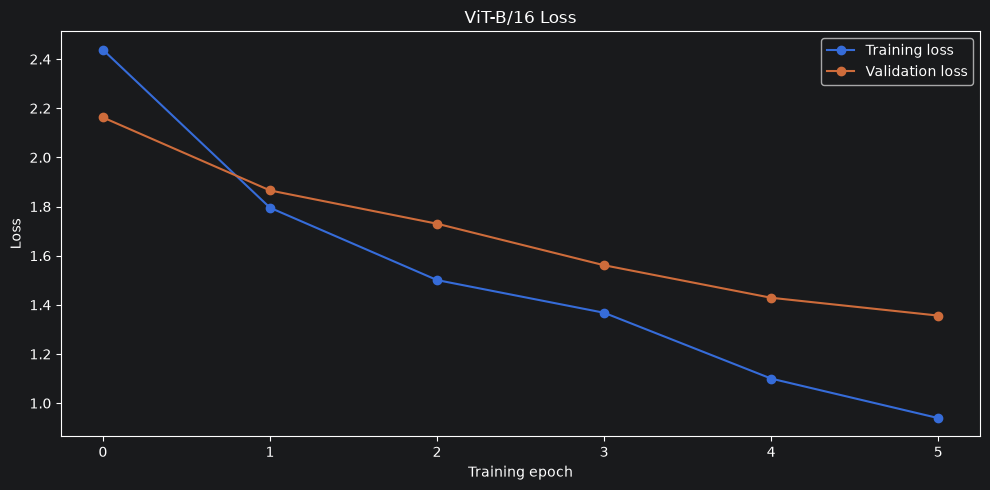

In [22]:
history = pd.DataFrame(history_stage1 + history_stage2)
display(history)

history.to_csv(REPORT_DIR / "training_history.csv", index=False)

plt.figure(figsize=(10, 5))
plt.plot(history["train_top1"].values, marker="o", label="Training Top-1")
plt.plot(history["val_top1"].values, marker="o", label="Validation Top-1")
plt.xlabel("Training epoch")
plt.ylabel("Accuracy")
plt.title("ViT-B/16 Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "accuracy_curve.png", dpi=160)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"].values, marker="o", label="Training loss")
plt.plot(history["val_loss"].values, marker="o", label="Validation loss")
plt.xlabel("Training epoch")
plt.ylabel("Loss")
plt.title("ViT-B/16 Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "loss_curve.png", dpi=160)
plt.show()


## 19. Held-out test evaluation

In [23]:
def collect_predictions(model, loader):
    model.eval()

    all_targets = []
    all_predictions = []
    all_probabilities = []

    with torch.inference_mode():
        for images, targets in tqdm(loader):
            images = images.to(DEVICE, non_blocking=True)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            all_targets.extend(targets.numpy())
            all_predictions.extend(probabilities.argmax(dim=1).cpu().numpy())
            all_probabilities.append(probabilities.cpu())

    return (
        np.asarray(all_targets),
        np.asarray(all_predictions),
        torch.cat(all_probabilities, dim=0),
    )

y_true, y_pred, probabilities = collect_predictions(model, test_loader)

top1 = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

top5_indices = probabilities.topk(min(5, NUM_CLASSES), dim=1).indices.numpy()
top5 = np.mean([
    true_target in predicted_top5
    for true_target, predicted_top5 in zip(y_true, top5_indices)
])

print(f"Test Top-1 accuracy: {top1:.4f}")
print(f"Test Top-5 accuracy: {top5:.4f}")
print(f"Test Macro F1:       {macro_f1:.4f}")


100%|██████████| 25/25 [04:57<00:00, 11.90s/it]

Test Top-1 accuracy: 0.7400
Test Top-5 accuracy: 0.9900
Test Macro F1:       0.7418


## 20. Classification report

In [24]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T
report_df.to_csv(REPORT_DIR / "classification_report.csv")
display(report_df)


,precision,recall,f1-score,support
Audi | Audi A5 coupe,0.470588,0.80,0.592593,10.00
Audi | Audi A5 hatchback,0.545455,0.60,0.571429,10.00
Audi | Audi A8L,0.777778,0.70,0.736842,10.00
BAW | BAW E Series hatchback,0.900000,0.90,0.900000,10.00
BWM | BWM 3 Series,0.461538,0.60,0.521739,10.00
BWM | BWM 5 Series,0.600000,0.30,0.400000,10.00
Benz | Benz E Class,0.800000,0.80,0.800000,10.00
Benz | Benz E Class couple,0.875000,0.70,0.777778,10.00
Buck | EXCELLE GT,1.000000,0.90,0.947368,10.00
Buck | Lacrosse,0.909091,1.00,0.952381,10.00


## 21. Confusion matrix

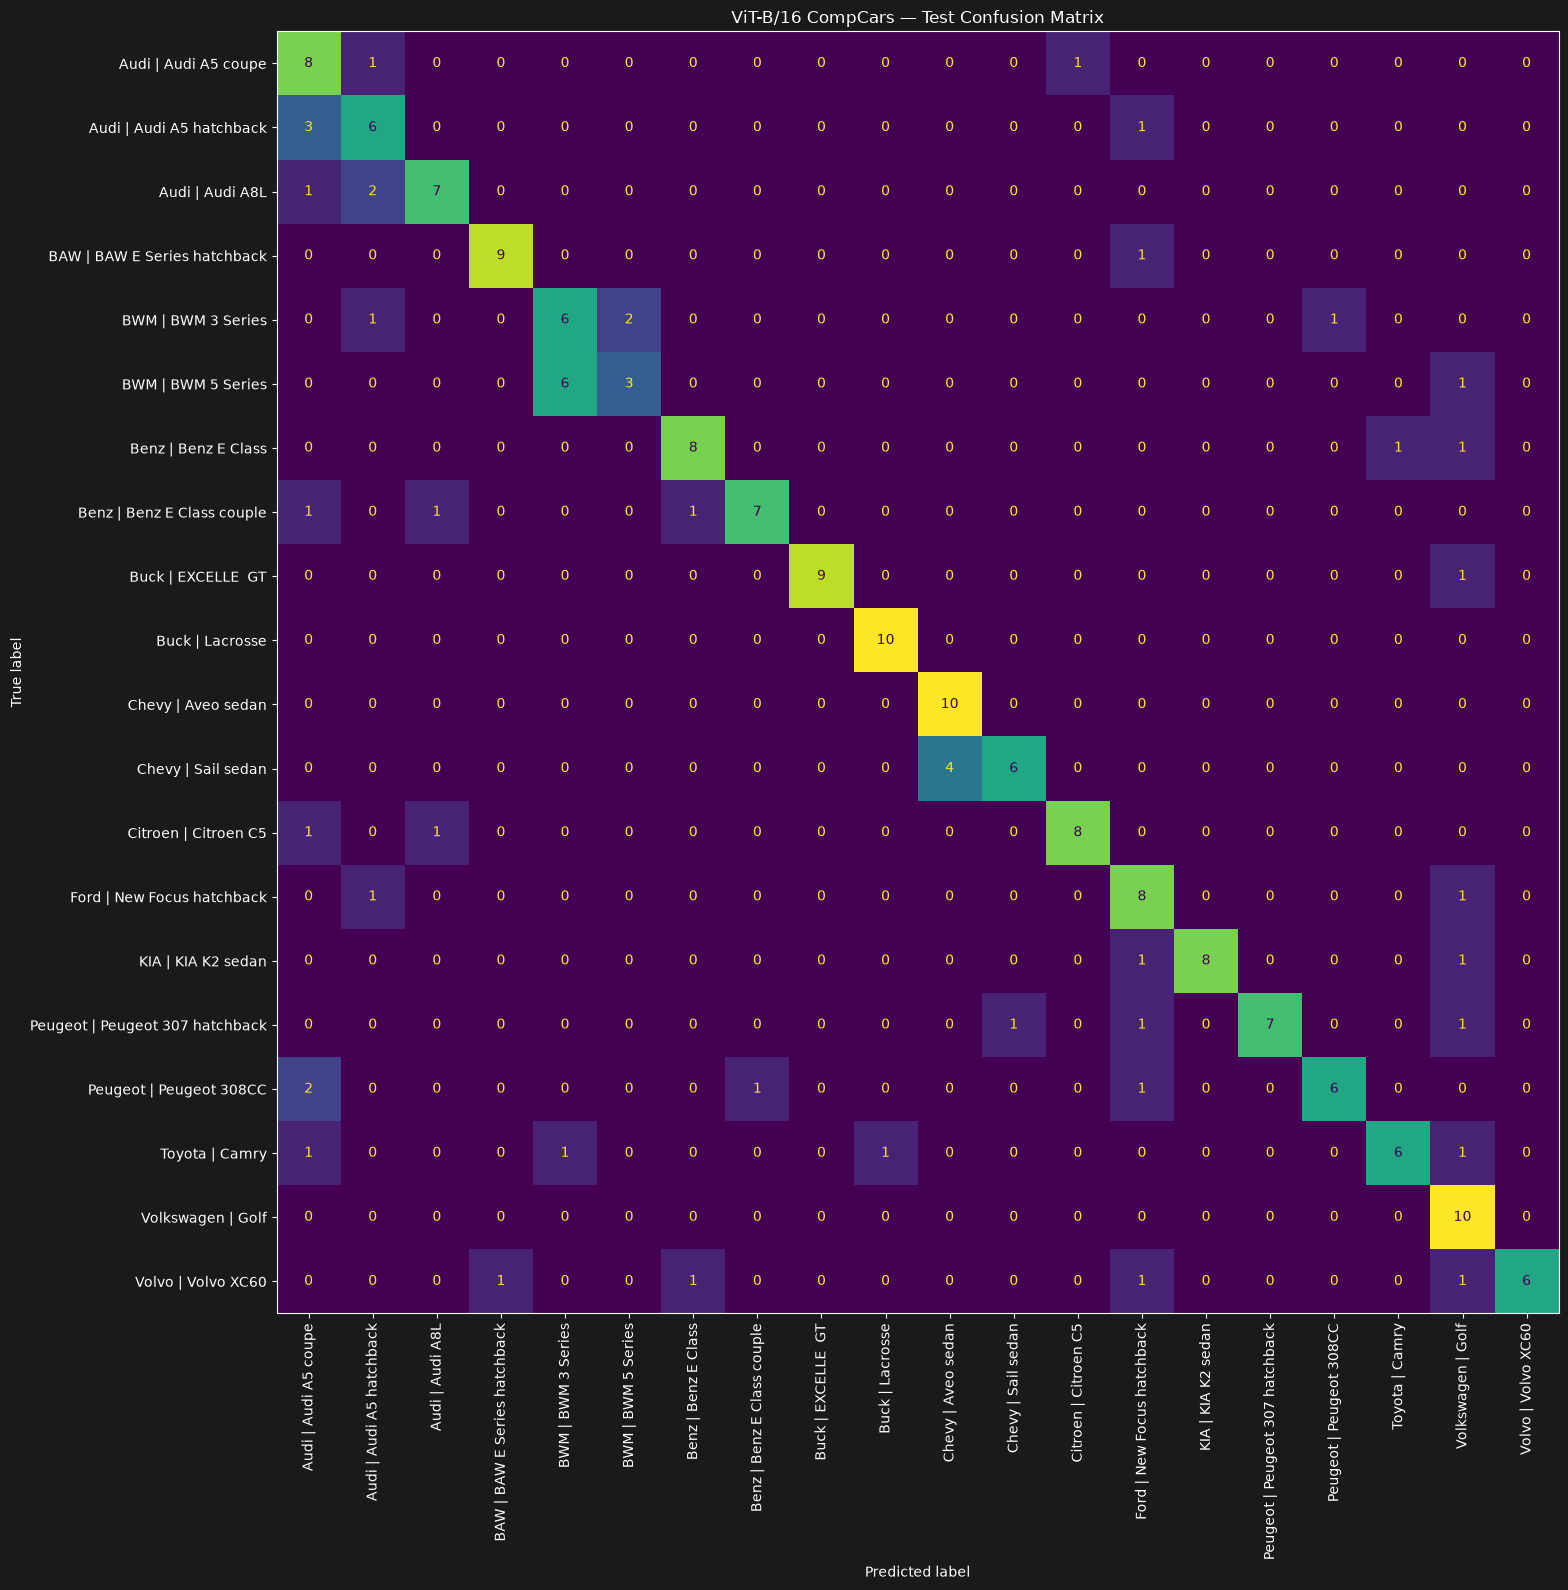

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(16, 16))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d",
)

ax.set_title("ViT-B/16 CompCars — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrix.png", dpi=160)
plt.show()


## 22. Prediction examples

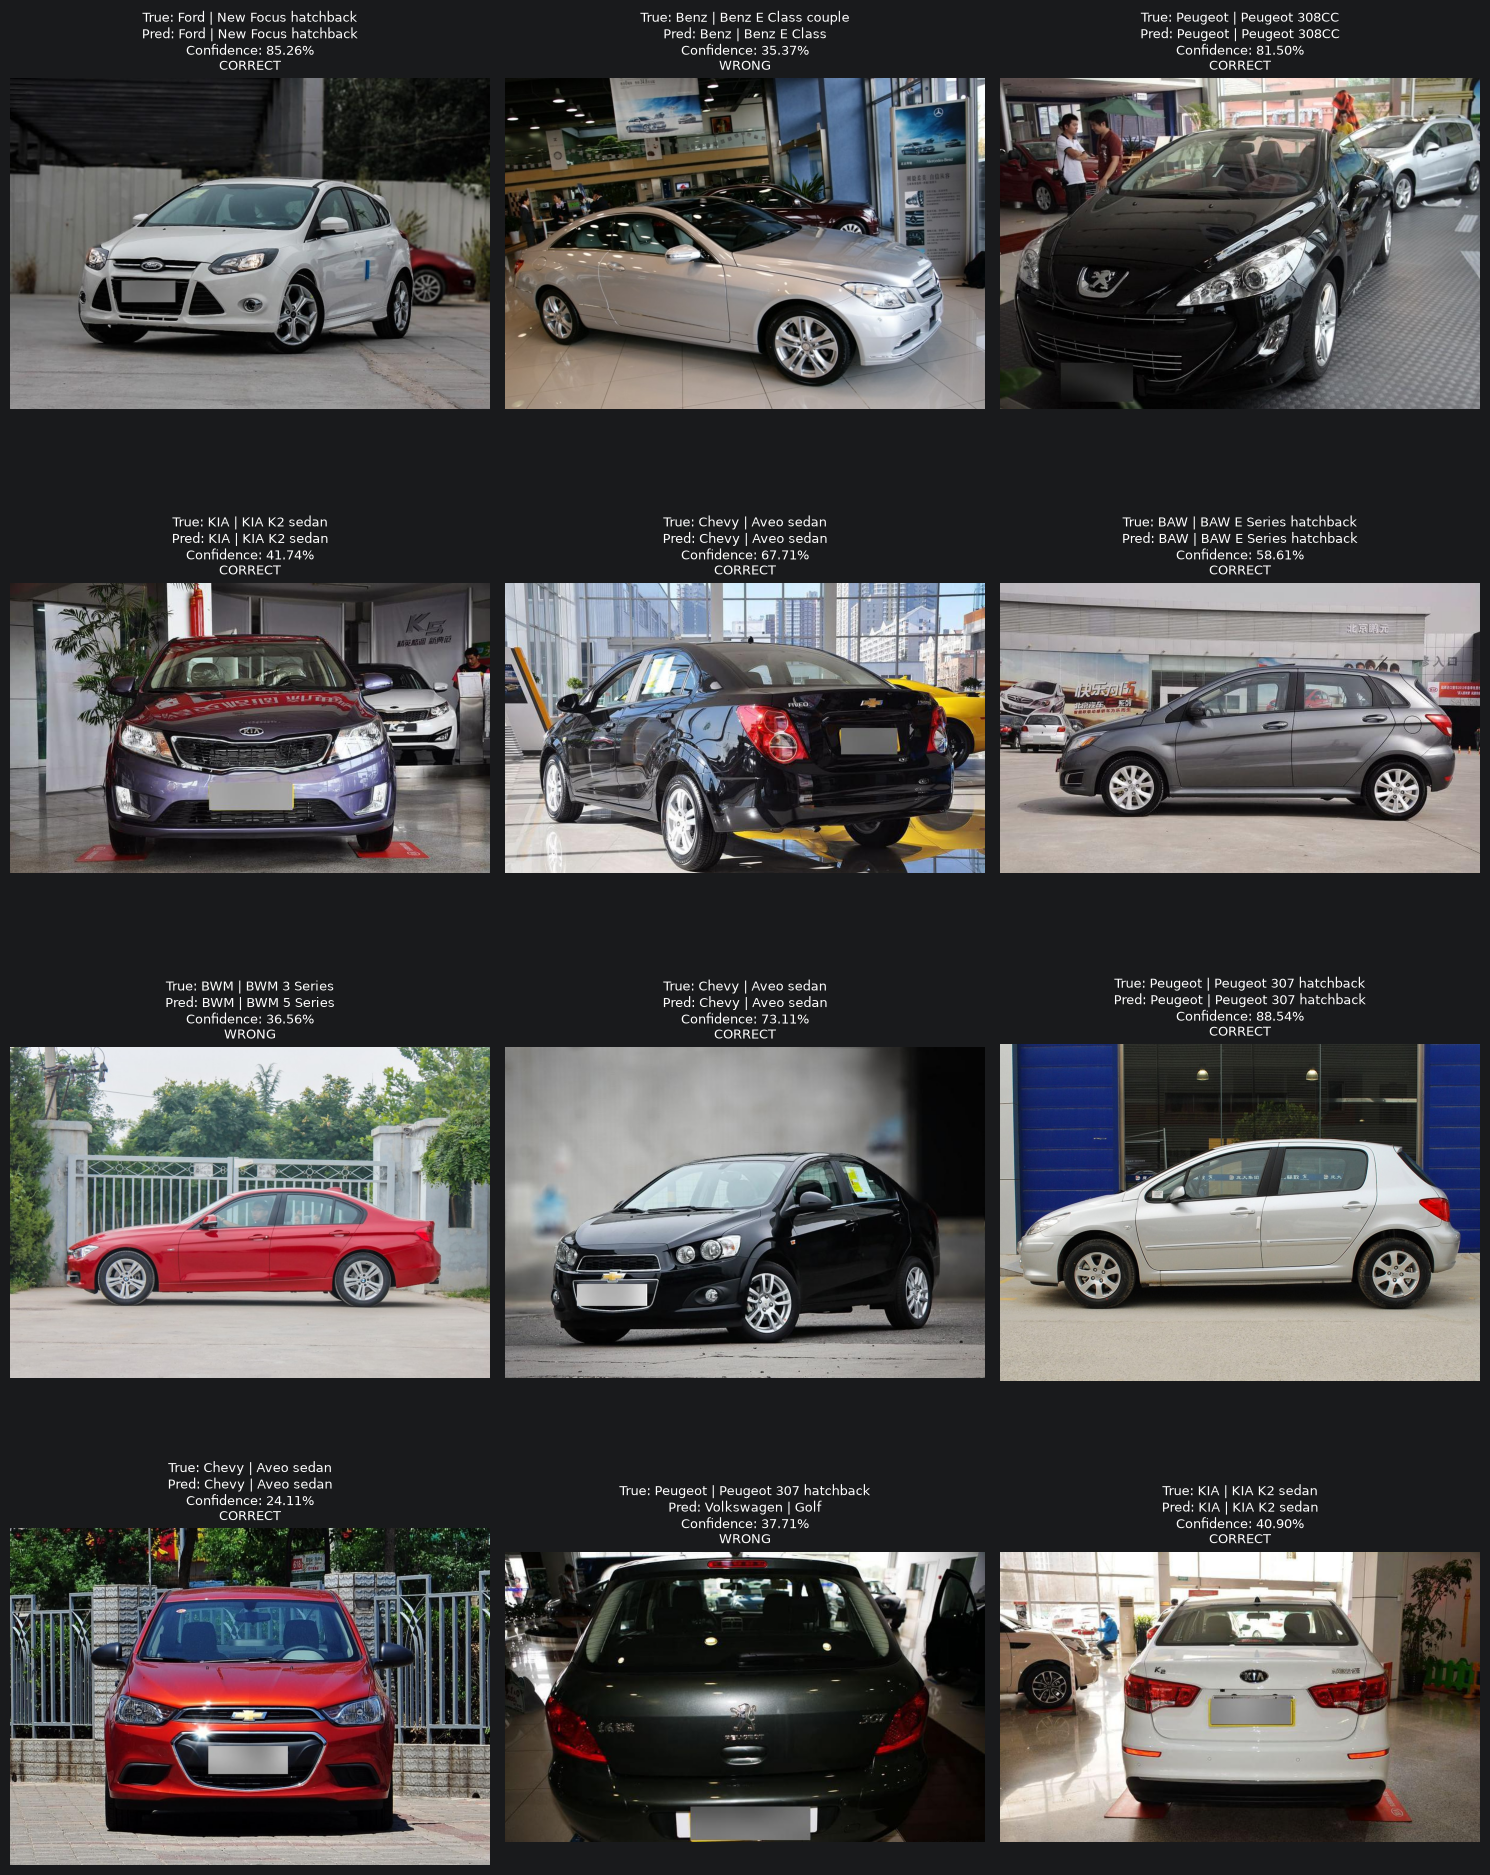

In [26]:
def show_test_predictions(n=12, random_state=SEED):
    local_test_df = test_df.reset_index(drop=True)
    sample_indices = (
        local_test_df
        .sample(min(n, len(local_test_df)), random_state=random_state)
        .index
        .tolist()
    )

    cols = 3
    rows = int(np.ceil(len(sample_indices) / cols))
    plt.figure(figsize=(15, 5 * rows))

    model.eval()

    for plot_number, dataframe_index in enumerate(sample_indices, start=1):
        row = local_test_df.iloc[dataframe_index]
        image = Image.open(row["local_file_path"]).convert("RGB")
        tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            probs = torch.softmax(model(tensor), dim=1)[0]

        confidence, predicted_index = probs.max(dim=0)
        predicted_label = class_names[predicted_index.item()]
        correct = predicted_index.item() == int(row["target"])

        plt.subplot(rows, cols, plot_number)
        plt.imshow(image)
        plt.title(
            f"True: {row['class_name']}\n"
            f"Pred: {predicted_label}\n"
            f"Confidence: {confidence.item():.2%}\n"
            f"{'CORRECT' if correct else 'WRONG'}",
            fontsize=9,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_test_predictions()


## 23. Saving ViT-B/16 model and metrics

In [27]:
MODEL_PATH = MODEL_DIR / "vit_b16_compcars_baseline.pt"

checkpoint = {
    "architecture": "vit_b_16",
    "task": "make_model_classification",
    "image_size": IMAGE_SIZE,
    "classes": class_names,
    "num_classes": NUM_CLASSES,
    "state_dict": model.state_dict(),
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "selected_stage": selected_stage,
    "validation_top1": float(selected_val_top1),
    "test_top1": float(top1),
    "test_top5": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": gpu_name,
}

torch.save(checkpoint, MODEL_PATH)

metrics = {
    "architecture": "ViT-B/16",
    "pretraining": "ImageNet",
    "classes": NUM_CLASSES,
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "batch_size": BATCH_SIZE,
    "selected_stage": selected_stage,
    "validation_top1_accuracy": float(selected_val_top1),
    "test_top1_accuracy": float(top1),
    "test_top5_accuracy": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": gpu_name,
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
}

with (REPORT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved reports:", REPORT_DIR)


Saved model: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\vit_b16_compcars_baseline.pt
Saved reports: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\baseline_vit_b16


## 24. ResNet50 vs ViT-B/16 comparison

In [28]:
RESNET_METRICS_PATH = (
    PROJECT_ROOT / "reports" / "baseline_resnet50" / "metrics.json"
)

if RESNET_METRICS_PATH.exists():
    with RESNET_METRICS_PATH.open("r", encoding="utf-8") as f:
        resnet_metrics = json.load(f)

    comparison = pd.DataFrame([
        {
            "Model": "ResNet50",
            "Test Top-1": resnet_metrics.get("test_top1_accuracy"),
            "Test Top-5": resnet_metrics.get("test_top5_accuracy"),
            "Macro F1": resnet_metrics.get("test_macro_f1"),
            "GPU": resnet_metrics.get("gpu"),
        },
        {
            "Model": "ViT-B/16",
            "Test Top-1": top1,
            "Test Top-5": top5,
            "Macro F1": macro_f1,
            "GPU": gpu_name,
        },
    ])

    display(comparison)
    comparison.to_csv(
        REPORT_DIR / "resnet50_vs_vit_b16.csv",
        index=False,
    )
else:
    print("ResNet50 metrics.json not found; comparison skipped.")


,Model,Test Top-1,Test Top-5,Macro F1,GPU
0,ResNet50,0.81,0.995,0.810771,NVIDIA GeForce RTX 2060
1,ViT-B/16,0.74,0.990,0.741829,NVIDIA GeForce RTX 5060 Laptop GPU
